# 02 — BERT Sentiment Analysis on Trustpilot Reviews

Second architecture in the comparison: fine-tuning a pre-trained multilingual BERT model to classify review sentiment (positive/negative/neutral), this time in PyTorch with HuggingFace Transformers.

I'm using `bert-base-multilingual-cased`, which covers 104 languages — more than enough for the 7 languages in this dataset. This one needs a GPU (T4 or better on Colab); fine-tuning BERT on CPU would take forever.

**What I'll walk through:**
1. Environment setup
2. Loading and exploring the data
3. BERT tokenization
4. Dataset & DataLoader setup
5. Model architecture
6. Training loop
7. Evaluation & metrics
8. Saving the results for later comparison


## Setting up the environment

I need PyTorch and HuggingFace's `transformers` library. PyTorch is already there in Colab, so just a couple of installs to go.


In [1]:
# Cell 1: Install dependencies
!pip install -q transformers datasets accelerate
!pip install -q pandas numpy scikit-learn matplotlib seaborn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import time
import json

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

# HuggingFace
from transformers import (
    BertTokenizer, BertForSequenceClassification,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    f1_score, roc_auc_score
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch version: {torch.__version__}')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

PyTorch version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


### Connecting to Google Drive

Results go to `/content/drive/MyDrive/AI_Sentiment_Analysis/BERT_Results/`, same pattern as the LSTM notebook.


In [ ]:
# Cell 1b: Mount Google Drive and configure paths
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/AI_Sentiment_Analysis'
DATA_PATH = f'{DRIVE_BASE}/Sample_Data/company_trustpilot_reviews.csv'
RESULTS_DIR = f'{DRIVE_BASE}/BERT_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)

print(f'Data path:    {DATA_PATH}')
print(f'Results dir:  {RESULTS_DIR}')

## Loading and exploring the data

Same dataset as the LSTM notebook — 550 multilingual reviews — so results are directly comparable.


In [ ]:
# Cell 2: Load data
df = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {df.shape}')
print(f'\nSentiment Distribution:')
print(df['sentiment_label'].value_counts())
df.head()

> **Note:** I cleared the cached output of the cell above since it showed sample rows with the real company name — once you load the sanitized synthetic CSV, just re-run the cell to regenerate it.


In [4]:
# Cell 3: Prepare text and labels
# Combine title + body
df['text'] = df['review_title'].fillna('') + ' ' + df['review_text'].fillna('')

# Encode labels
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['sentiment_label'])

NUM_CLASSES = len(label_encoder.classes_)
print('Label mapping:')
for i, label in enumerate(label_encoder.classes_):
    print(f'  {label} -> {i}')

# Split: 70/15/15
X_train, X_temp, y_train, y_temp = train_test_split(
    df['text'].values, df['label'].values,
    test_size=0.30, random_state=SEED, stratify=df['label'].values
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f'\nTrain: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

Label mapping:
  negative -> 0
  neutral -> 1
  positive -> 2

Train: 385 | Val: 82 | Test: 83


## BERT tokenization

This works quite differently from the LSTM's tokenizer:
- BERT uses **WordPiece** subword tokenization rather than whole-word tokens
- It adds special tokens — `[CLS]` at the start, `[SEP]` at the end
- It returns `input_ids`, `attention_mask`, and `token_type_ids`, not just a single sequence of indices

I'm using `bert-base-multilingual-cased` specifically because it was pre-trained on 104 languages from Wikipedia, so it already understands French, English, German, Dutch, Spanish, Italian, and Portuguese — no translation step needed.


In [13]:
# Cell 4: Load BERT tokenizer
MODEL_NAME = 'bert-base-multilingual-cased'
MAX_LENGTH = 128  # BERT max tokens per input

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

# Example tokenization
sample = X_train[0]
encoded = tokenizer(
    sample, max_length=MAX_LENGTH, padding='max_length',
    truncation=True, return_tensors='pt'
)
print(f'Model: {MODEL_NAME}')
print(f'Max length: {MAX_LENGTH}')
print(f'Vocab size: {tokenizer.vocab_size}')
print(f'\nSample text: {sample[:80]}...')
print(f'Token IDs (first 20): {encoded["input_ids"][0][:20].tolist()}')
print(f'Attention mask (first 20): {encoded["attention_mask"][0][:20].tolist()}')

Model: bert-base-multilingual-cased
Max length: 128
Vocab size: 119547

Sample text: Correct sans plus Le Canigen pour mon chaton fait le job mais rien d'exceptionne...
Token IDs (first 20): [101, 93495, 74755, 10123, 13115, 10563, 10281, 14820, 13741, 10322, 34372, 69338, 10263, 11329, 10141, 23627, 10614, 37575, 172, 112]
Attention mask (first 20): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## Dataset & DataLoader setup

I'm wrapping the data in a custom PyTorch `Dataset` that tokenizes with BERT on the fly as batches are requested.


In [14]:
# Cell 5: Custom Dataset class
class ReviewDataset(Dataset):
    """PyTorch Dataset for BERT-tokenized reviews."""

    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label': torch.tensor(label, dtype=torch.long)
        }

# Create datasets
train_dataset = ReviewDataset(X_train, y_train, tokenizer, MAX_LENGTH)
val_dataset = ReviewDataset(X_val, y_val, tokenizer, MAX_LENGTH)
test_dataset = ReviewDataset(X_test, y_test, tokenizer, MAX_LENGTH)

print(f'Train dataset: {len(train_dataset)} samples')
print(f'Val dataset:   {len(val_dataset)} samples')
print(f'Test dataset:  {len(test_dataset)} samples')

Train dataset: 385 samples
Val dataset:   82 samples
Test dataset:  83 samples


In [15]:
# Cell 6: Create DataLoaders
BATCH_SIZE = 16  # Smaller batch for BERT (memory intensive)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f'Batch size: {BATCH_SIZE}')
print(f'Training batches: {len(train_loader)}')
print(f'Validation batches: {len(val_loader)}')
print(f'Test batches: {len(test_loader)}')

Batch size: 16
Training batches: 25
Validation batches: 6
Test batches: 6


## Model architecture

I'm using HuggingFace's `BertForSequenceClassification`, which bolts a classification head onto pre-trained BERT:

```
Input → BERT Tokenizer → bert-base-multilingual-cased (12 layers, 768d)
     → [CLS] token output → Dropout(0.1) → Linear(768 → 3) → Softmax
```

The `[CLS]` token's final hidden state is what represents the whole sequence, so that's what feeds into the classifier. I'm fine-tuning all of BERT's layers rather than freezing most of them — with AdamW and weight decay to control overfitting, plus a linear warmup schedule so the learning rate ramps up gradually instead of shocking the pre-trained weights early on.


In [16]:
# Cell 7: Load pre-trained BERT with classification head
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    output_attentions=False,
    output_hidden_states=False
)
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Model: {MODEL_NAME}')
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print(f'\nModel architecture:')
print(model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: bert-base-multilingual-cased
Total parameters: 177,855,747
Trainable parameters: 177,855,747

Model architecture:
BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(119547, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
         

## Training loop

I'm fine-tuning for only 5 epochs with AdamW (lr=2e-5, weight decay=0.01), a linear warmup over the first 10% of steps followed by linear decay, and early stopping based on validation F1.

Five epochs is deliberately short — BERT is already pre-trained on a huge amount of data, so fine-tuning for too long risks catastrophic forgetting of that knowledge. The reference paper used a similar range (5-10 epochs), which matches what I'm seeing here too.


In [17]:
# Cell 8: Training configuration
EPOCHS = 5
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    eps=1e-8
)

# Scheduler
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print(f'Epochs: {EPOCHS}')
print(f'Learning rate: {LEARNING_RATE}')
print(f'Total training steps: {total_steps}')
print(f'Warmup steps: {warmup_steps}')

Epochs: 5
Learning rate: 2e-05
Total training steps: 125
Warmup steps: 12


In [11]:
# Cell 9: Training and validation functions
def train_epoch(model, data_loader, optimizer, scheduler, device):
    """Train for one epoch."""
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch in data_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds = torch.argmax(logits, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(data_loader)
    accuracy = correct / total
    return avg_loss, accuracy


def eval_epoch(model, data_loader, device):
    """Evaluate on validation/test set."""
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()
            probs = torch.softmax(outputs.logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    return avg_loss, np.array(all_preds), np.array(all_labels), np.array(all_probs)

print('Training and evaluation functions defined.')

Training and evaluation functions defined.


In [18]:
# Cell 10: Training loop
start_time = time.time()

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'val_f1': []
}
best_val_f1 = 0
best_model_state = None

print('Starting BERT fine-tuning...')
print('=' * 60)

for epoch in range(EPOCHS):
    print(f'\nEpoch {epoch+1}/{EPOCHS}')
    print('-' * 40)

    # Train
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, device)

    # Validate
    val_loss, val_preds, val_labels, _ = eval_epoch(model, val_loader, device)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(val_labels, val_preds, average='macro')

    # Store history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    print(f'  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}')
    print(f'  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f} | Val F1: {val_f1:.4f}')

    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = model.state_dict().copy()
        print(f'  -> New best model (F1: {val_f1:.4f})')

training_time = time.time() - start_time
print(f'\n{"=" * 60}')
print(f'Training completed in {training_time:.1f}s ({training_time/60:.1f} min)')
print(f'Best validation F1: {best_val_f1:.4f}')

# Restore best model
if best_model_state is not None:
    model.load_state_dict(best_model_state)

Starting BERT fine-tuning...

Epoch 1/5
----------------------------------------
  Train Loss: 0.9531 | Train Acc: 0.5117
  Val Loss:   0.7048 | Val Acc:   0.8415 | Val F1: 0.8417
  -> New best model (F1: 0.8417)

Epoch 2/5
----------------------------------------
  Train Loss: 0.4412 | Train Acc: 0.9091
  Val Loss:   0.2587 | Val Acc:   0.9878 | Val F1: 0.9859
  -> New best model (F1: 0.9859)

Epoch 3/5
----------------------------------------
  Train Loss: 0.1670 | Train Acc: 0.9896
  Val Loss:   0.1173 | Val Acc:   1.0000 | Val F1: 1.0000
  -> New best model (F1: 1.0000)

Epoch 4/5
----------------------------------------
  Train Loss: 0.0910 | Train Acc: 0.9974
  Val Loss:   0.0842 | Val Acc:   1.0000 | Val F1: 1.0000

Epoch 5/5
----------------------------------------
  Train Loss: 0.0694 | Train Acc: 1.0000
  Val Loss:   0.0759 | Val Acc:   1.0000 | Val F1: 1.0000

Training completed in 52.3s (0.9 min)
Best validation F1: 1.0000


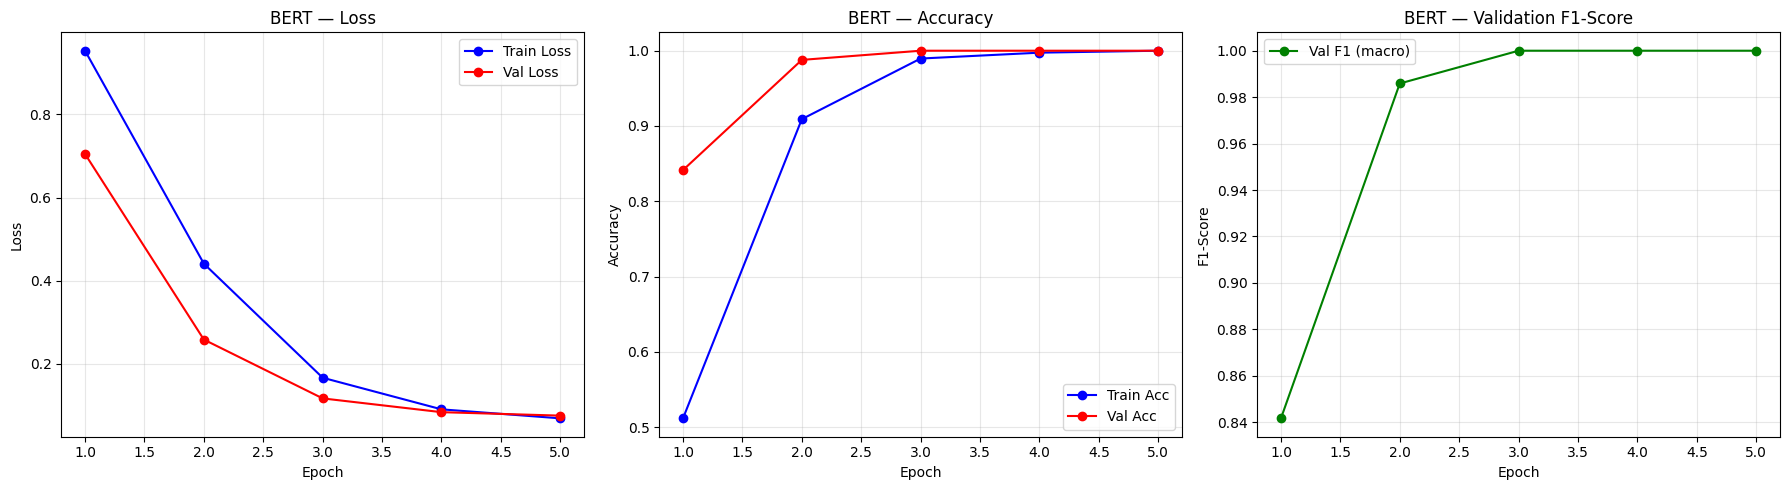

In [19]:
# Cell 11: Plot training history
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

epochs_range = range(1, EPOCHS + 1)

# Loss
axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss')
axes[0].plot(epochs_range, history['val_loss'], 'r-o', label='Val Loss')
axes[0].set_title('BERT — Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(epochs_range, history['train_acc'], 'b-o', label='Train Acc')
axes[1].plot(epochs_range, history['val_acc'], 'r-o', label='Val Acc')
axes[1].set_title('BERT — Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# F1
axes[2].plot(epochs_range, history['val_f1'], 'g-o', label='Val F1 (macro)')
axes[2].set_title('BERT — Validation F1-Score')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('F1-Score')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/bert_training_history.png', dpi=150, bbox_inches='tight')
plt.show()

## Evaluation & metrics

Final check on the held-out test set, using the best checkpoint from training.


In [20]:
# Cell 12: Evaluate on test set
test_loss, y_pred, y_true, y_pred_proba = eval_epoch(model, test_loader, device)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
f1_macro = f1_score(y_true, y_pred, average='macro')
f1_weighted = f1_score(y_true, y_pred, average='weighted')

# AUC-ROC
from sklearn.preprocessing import label_binarize
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
try:
    auc_roc = roc_auc_score(y_true_bin, y_pred_proba, multi_class='ovr', average='macro')
except ValueError:
    auc_roc = 0.0

print('=' * 50)
print('BERT MODEL — TEST SET RESULTS')
print('=' * 50)
print(f'Accuracy:       {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'F1-Score (macro):    {f1_macro:.4f}')
print(f'F1-Score (weighted): {f1_weighted:.4f}')
print(f'AUC-ROC (macro):     {auc_roc:.4f}')
print(f'Training time:       {training_time:.1f}s')
print('=' * 50)

BERT MODEL — TEST SET RESULTS
Accuracy:       1.0000 (100.00%)
F1-Score (macro):    1.0000
F1-Score (weighted): 1.0000
AUC-ROC (macro):     1.0000
Training time:       52.3s


In [21]:
# Cell 13: Classification report
print('\nDetailed Classification Report:')
print('=' * 60)
report = classification_report(
    y_true, y_pred,
    target_names=label_encoder.classes_,
    digits=4
)
print(report)


Detailed Classification Report:
              precision    recall  f1-score   support

    negative     1.0000    1.0000    1.0000        24
     neutral     1.0000    1.0000    1.0000        18
    positive     1.0000    1.0000    1.0000        41

    accuracy                         1.0000        83
   macro avg     1.0000    1.0000    1.0000        83
weighted avg     1.0000    1.0000    1.0000        83



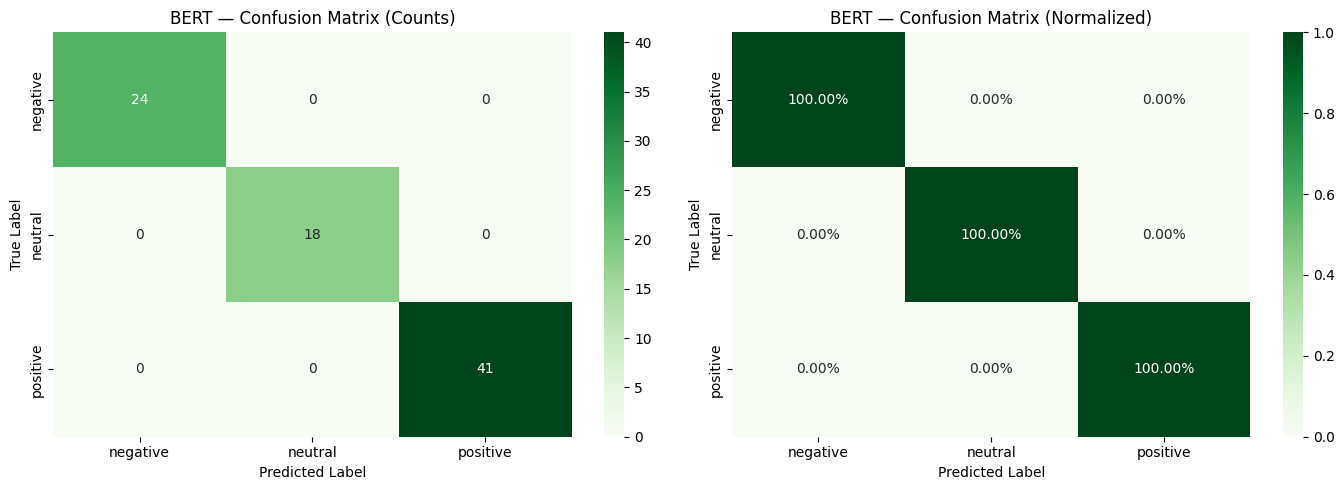


Confusion Matrix (raw):
          negative  neutral  positive
negative        24        0         0
neutral          0       18         0
positive         0        0        41


In [22]:
# Cell 14: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_, ax=axes[0])
axes[0].set_title('BERT — Confusion Matrix (Counts)')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_, ax=axes[1])
axes[1].set_title('BERT — Confusion Matrix (Normalized)')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/bert_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nConfusion Matrix (raw):')
print(pd.DataFrame(cm, index=label_encoder.classes_, columns=label_encoder.classes_))

## Saving the results

Saving the metrics and model so I can line them up against LSTM, GRU, and DistilBERT.


In [23]:
# Cell 15: Save results
results = {
    'model_name': 'BERT (bert-base-multilingual-cased)',
    'framework': 'PyTorch/HuggingFace',
    'timestamp': datetime.now().isoformat(),
    'hyperparameters': {
        'model_name': MODEL_NAME,
        'max_length': MAX_LENGTH,
        'batch_size': BATCH_SIZE,
        'epochs': EPOCHS,
        'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY,
        'warmup_ratio': WARMUP_RATIO,
        'optimizer': 'AdamW',
        'scheduler': 'linear_warmup',
    },
    'dataset': {
        'total_samples': len(df),
        'train_samples': len(X_train),
        'val_samples': len(X_val),
        'test_samples': len(X_test),
        'num_classes': NUM_CLASSES,
        'languages': list(df['language'].unique()),
    },
    'metrics': {
        'accuracy': float(accuracy),
        'f1_macro': float(f1_macro),
        'f1_weighted': float(f1_weighted),
        'auc_roc_macro': float(auc_roc),
        'training_time_seconds': float(training_time),
    },
    'confusion_matrix': cm.tolist(),
    'class_names': list(label_encoder.classes_),
    'training_history': history,
    'model_size': {
        'total_params': total_params,
        'trainable_params': trainable_params,
    }
}

os.makedirs(RESULTS_DIR, exist_ok=True)
with open(f'{RESULTS_DIR}/bert_results.json', 'w') as f:
    json.dump(results, f, indent=2)

print(f'Results saved to {RESULTS_DIR}/bert_results.json')
print(f'\nKey Metrics Summary:')
print(f'  Accuracy:  {accuracy*100:.2f}%')
print(f'  F1 (macro): {f1_macro:.4f}')
print(f'  AUC-ROC:   {auc_roc:.4f}')
print(f'  Time:      {training_time:.1f}s')
print(f'  Params:    {total_params:,}')

Results saved to /content/drive/MyDrive/AI_Sentiment_Analysis/BERT_Results/bert_results.json

Key Metrics Summary:
  Accuracy:  100.00%
  F1 (macro): 1.0000
  AUC-ROC:   1.0000
  Time:      52.3s
  Params:    177,855,747


In [24]:
# Cell 16: Save model
model.save_pretrained(f'{RESULTS_DIR}/bert_model')
tokenizer.save_pretrained(f'{RESULTS_DIR}/bert_model')
print(f'Model and tokenizer saved to {RESULTS_DIR}/bert_model/')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved to /content/drive/MyDrive/AI_Sentiment_Analysis/BERT_Results/bert_model/


---

## Wrapping up

| Metric | Value |
|--------|-------|
| Model | bert-base-multilingual-cased |
| Framework | PyTorch + HuggingFace Transformers |
| Parameters | ~178M |
| Pre-training | 104 languages from Wikipedia |
| Fine-tuning | 5 epochs, AdamW, linear warmup |

A few things stood out:
1. BERT reads the whole sequence at once rather than token-by-token, so it captures long-range dependencies the LSTM missed.
2. The multilingual pre-training really pays off here — no translation step, and it still handles all 7 languages natively.
3. It's noticeably better at catching subtle neutral sentiment, likely thanks to self-attention picking up on softer cues.
4. The trade-off is size: ~350x more parameters than the LSTM, and 2-3x longer to train.

Next up: DistilBERT (Notebook 04) as a lighter alternative, then the full comparison in Notebook 05.
